# CIE-1 Milestone 1: Zomato Restaurant Data Analysis

**Subject:** Skill Lab (Python & Pandas Data Analysis)  
**Goal:** Load and explore a Zomato restaurants CSV dataset, apply data transformations, handle missing values with mean imputation, extract practical business insights, and create clear visualizations.

### Dataset Overview
For this assignment, I selected `zomato_restaurants_data.csv` (550 restaurant records across major Indian cities) to study how pricing, delivery speed, online ordering, and cuisine types impact customer ratings and monthly order volumes.

## Step 1: Dataset Selection and Reading
First, we import `pandas`, `numpy`, `matplotlib.pyplot`, and `seaborn`, and then read `zomato_restaurants_data.csv` using `pd.read_csv()`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure default plot styling
sns.set_style("darkgrid")
plt.rcParams["figure.figsize"] = (9.5, 5)

# Load the Zomato CSV file
zomato_data = pd.read_csv("zomato_restaurants_data.csv")

# Preview the top 5 rows
print("Zomato dataset loaded successfully!")
zomato_data.head()

Zomato dataset loaded successfully!

,Restaurant_ID,Restaurant_Name,City,Cuisine_Type,Established_Year,Online_Order,Table_Booking,Avg_Cost_For_Two,Avg_Delivery_Time_Mins,Discount_Percent,Customer_Rating,Total_Votes,Monthly_Orders,FSSAI_Batch_Code,Internal_Audit_Notes
0,ZMT-5001,Coastal Grill 1,Pune,North Indian,2025,No,No,1220.0,46.2,29.8,3.5,984.0,2024.0,FSSAI-REG-542122,Verified menu v1
1,ZMT-5002,Royal Express 2,Bengaluru,Chinese & Asian,2020,No,Yes,896.0,33.9,25.7,4.3,824.0,2311.0,FSSAI-REG-628982,Verified menu v1
2,ZMT-5003,Namma Corner 3,Hyderabad,North Indian,2018,Yes,No,NaN,29.6,39.3,3.9,728.0,1916.0,FSSAI-REG-425119,Standard listing
3,ZMT-5004,Urban Diner 4,Mangaluru,South Indian,2024,Yes,Yes,897.0,34.5,22.7,3.8,873.0,1932.0,FSSAI-REG-748793,Onboarding complete
4,ZMT-5005,Urban Hub 5,Bengaluru,South Indian,2023,Yes,Yes,1398.0,46.5,35.4,4.4,960.0,NaN,FSSAI-REG-279786,Partner tier B


## Step 2: Data Understanding
Let's examine the dataset dimensions, column names, data types, and summary statistics to understand its structure before cleaning it.

In [2]:
# Check rows, columns, and column headers
rows, cols = zomato_data.shape
print(f"Number of Records (Rows): {rows}")
print(f"Number of Features (Columns): {cols}")
print("\nColumn List:", zomato_data.columns.tolist())

Number of Records (Rows): 550
Number of Features (Columns): 15

Column List: ['Restaurant_ID', 'Restaurant_Name', 'City', 'Cuisine_Type', 'Established_Year', 'Online_Order', 'Table_Booking', 'Avg_Cost_For_Two', 'Avg_Delivery_Time_Mins', 'Discount_Percent', 'Customer_Rating', 'Total_Votes', 'Monthly_Orders', 'FSSAI_Batch_Code', 'Internal_Audit_Notes']

In [3]:
# Check data types and non-null counts
zomato_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Restaurant_ID           550 non-null    object 
 1   Restaurant_Name         550 non-null    object 
 2   City                    550 non-null    object 
 3   Cuisine_Type            550 non-null    object 
 4   Established_Year        550 non-null    int64  
 5   Online_Order            550 non-null    object 
 6   Table_Booking           550 non-null    object 
 7   Avg_Cost_For_Two        519 non-null    float64
 8   Avg_Delivery_Time_Mins  529 non-null    float64
 9   Discount_Percent        550 non-null    float64
 10  Customer_Rating         524 non-null    float64
 11  Total_Votes             532 non-null    float64
 12  Monthly_Orders          526 non-null    float64
 13  FSSAI_Batch_Code        550 non-null    object 
 14  Internal_Audit_Notes    550 non-null    ob

In [4]:
# Statistical summary of numerical columns
zomato_data.describe().round(2)

,Established_Year,Avg_Cost_For_Two,Avg_Delivery_Time_Mins,Discount_Percent,Customer_Rating,Total_Votes,Monthly_Orders
count,550.00,519.00,529.00,550.00,524.00,532.00,526.00
mean,2020.04,979.45,33.44,22.43,3.79,904.65,1853.23
std,3.20,465.68,7.41,10.12,0.39,215.55,255.81
min,2015.00,150.00,18.00,5.10,2.60,498.00,1132.00
25%,2017.00,554.00,28.80,13.20,3.50,767.00,1695.00
50%,2020.00,976.00,32.90,22.90,3.80,863.00,1862.50
75%,2023.00,1383.50,38.20,31.20,4.10,1005.25,2018.75
max,2025.00,1793.00,59.00,40.00,4.90,2188.00,2579.00


In [5]:
# Check unique cities and cuisine categories covered in the dataset
print("Cities Covered:", zomato_data["City"].unique())
print("Cuisine Types:", zomato_data["Cuisine_Type"].unique())

Cities Covered: ['Pune' 'Bengaluru' 'Hyderabad' 'Mangaluru' 'Mumbai' 'Chennai' 'Delhi NCR'
 'Mysuru']
Cuisine Types: ['North Indian' 'Chinese & Asian' 'South Indian' 'Fast Food & Burgers'
 'Italian & Pizza' 'Cafe & Desserts' 'Biryani & Mughlai' 'Coastal Seafood']

### Key Points from Data Understanding:
- The dataset contains **550 restaurants** across **8 cities** (`Bengaluru`, `Mangaluru`, `Mumbai`, `Hyderabad`, `Pune`, `Chennai`, `Delhi NCR`, and `Mysuru`) with **15 columns**.
- Two columns (`FSSAI_Batch_Code` and `Internal_Audit_Notes`) are administrative codes that are not needed for analysis.
- Five numerical columns (`Avg_Cost_For_Two`, `Avg_Delivery_Time_Mins`, `Customer_Rating`, `Total_Votes`, and `Monthly_Orders`) contain missing (`NaN`) values that need to be filled using **mean imputation**.
- We can calculate `Cost_Per_Person` from `Avg_Cost_For_Two` and create a `Price_Bracket` column to compare budget vs. premium dining.

## Step 3: Data Transformation
Before imputing missing values and analyzing trends, let's perform our data transformations:
1. **Drop unnecessary columns:** Remove `FSSAI_Batch_Code` and `Internal_Audit_Notes`.
2. **Convert data types:** Ensure `Established_Year` is numeric (`int64`) and convert `Online_Order` into a binary flag (`1` for Yes, `0` for No) alongside the text column.
3. **Add new columns:**Create `Online_Order_Flag` now, and right after handling missing values in Step 4, compute `Cost_Per_Person` and `Est_Monthly_Revenue`.

In [6]:
# 1. Drop unused administrative columns
zomato_data.drop(columns=["FSSAI_Batch_Code", "Internal_Audit_Notes"], inplace=True)
print("Columns after dropping unnecessary ones:")
print(zomato_data.columns.tolist())

Columns after dropping unnecessary ones:
['Restaurant_ID', 'Restaurant_Name', 'City', 'Cuisine_Type', 'Established_Year', 'Online_Order', 'Table_Booking', 'Avg_Cost_For_Two', 'Avg_Delivery_Time_Mins', 'Discount_Percent', 'Customer_Rating', 'Total_Votes', 'Monthly_Orders']

In [7]:
# 2. Convert Established_Year to integer type
zomato_data["Established_Year"] = pd.to_numeric(zomato_data["Established_Year"], errors="coerce").astype("int64")

# 3. Add a new column: Restaurant Age (in years as of 2026) and Online Order binary indicator
zomato_data["Restaurant_Age_Years"] = 2026 - zomato_data["Established_Year"]
zomato_data["Online_Order_Flag"] = zomato_data["Online_Order"].map({"Yes": 1, "No": 0})

zomato_data[["Restaurant_Name", "City", "Established_Year", "Restaurant_Age_Years", "Online_Order", "Online_Order_Flag"]].head()

,Restaurant_Name,City,Established_Year,Restaurant_Age_Years,Online_Order,Online_Order_Flag
0,Coastal Grill 1,Pune,2025,1,No,0
1,Royal Express 2,Bengaluru,2020,6,No,0
2,Namma Corner 3,Hyderabad,2018,8,Yes,1
3,Urban Diner 4,Mangaluru,2024,2,Yes,1
4,Urban Hub 5,Bengaluru,2023,3,Yes,1


## Step 4: Handling Null Values (Mean Imputation)
Let's inspect the missing value counts in our dataset, apply **mean imputation** to fill all missing numerical values, and then compute our derived pricing columns (`Cost_Per_Person` and `Price_Bracket`).

In [8]:
# Check null counts in every column before imputation
print("Null values BEFORE mean imputation:")
print(zomato_data.isnull().sum())

Null values BEFORE mean imputation:
Restaurant_ID              0
Restaurant_Name            0
City                       0
Cuisine_Type               0
Established_Year           0
Online_Order               0
Table_Booking              0
Avg_Cost_For_Two          31
Avg_Delivery_Time_Mins    21
Discount_Percent           0
Customer_Rating           26
Total_Votes               18
Monthly_Orders            24
Restaurant_Age_Years       0
Online_Order_Flag          0
dtype: int64

In [9]:
# Numerical columns containing missing values
numeric_null_cols = [
    "Avg_Cost_For_Two",
    "Avg_Delivery_Time_Mins",
    "Customer_Rating",
    "Total_Votes",
    "Monthly_Orders"
]

# Apply Mean Imputation to each column
for col in numeric_null_cols:
    col_mean = zomato_data[col].mean()
    zomato_data[col] = zomato_data[col].fillna(round(col_mean, 1))
    print(f"Replaced NaNs in '{col}' with column mean: {col_mean:.2f}")

# Confirm zero null values remain
print("\nNull values AFTER mean imputation:")
print(zomato_data.isnull().sum())

Replaced NaNs in 'Avg_Cost_For_Two' with column mean: 979.45
Replaced NaNs in 'Avg_Delivery_Time_Mins' with column mean: 33.44
Replaced NaNs in 'Customer_Rating' with column mean: 3.79
Replaced NaNs in 'Total_Votes' with column mean: 904.65
Replaced NaNs in 'Monthly_Orders' with column mean: 1853.23

Null values AFTER mean imputation:
Restaurant_ID             0
Restaurant_Name           0
City                      0
Cuisine_Type              0
Established_Year          0
Online_Order              0
Table_Booking             0
Avg_Cost_For_Two          0
Avg_Delivery_Time_Mins    0
Discount_Percent          0
Customer_Rating           0
Total_Votes               0
Monthly_Orders            0
Restaurant_Age_Years      0
Online_Order_Flag         0
dtype: int64

In [10]:
# Add derived cost columns using the imputed Avg_Cost_For_Two column
zomato_data["Cost_Per_Person"] = (zomato_data["Avg_Cost_For_Two"] / 2).round(2)

# Categorize restaurants into Budget, Mid-Range, and Fine Dining
zomato_data["Price_Bracket"] = pd.cut(
    zomato_data["Avg_Cost_For_Two"],
    bins=[0, 500, 1100, 3000],
    labels=["Budget (<=500)", "Mid-Range (501-1100)", "Premium (>1100)"]
)

zomato_data[["Restaurant_Name", "Avg_Cost_For_Two", "Cost_Per_Person", "Price_Bracket"]].head()

,Restaurant_Name,Avg_Cost_For_Two,Cost_Per_Person,Price_Bracket
0,Coastal Grill 1,1220.0,610.00,Premium (>1100)
1,Royal Express 2,896.0,448.00,Mid-Range (501-1100)
2,Namma Corner 3,979.5,489.75,Mid-Range (501-1100)
3,Urban Diner 4,897.0,448.50,Mid-Range (501-1100)
4,Urban Hub 5,1398.0,699.00,Premium (>1100)


## Step 5: Insight Generation
Now let's analyze the cleaned dataset to uncover insights across cities, cuisines, and online ordering options.

In [11]:
# Insight 1: City-wise Restaurant Analysis (Count, Avg Cost, Avg Rating, and Total Monthly Orders)
city_analysis = zomato_data.groupby("City").agg(
    Restaurant_Count=("Restaurant_ID", "count"),
    Avg_Cost_For_Two=("Avg_Cost_For_Two", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
    Avg_Delivery_Mins=("Avg_Delivery_Time_Mins", "mean"),
    Total_Monthly_Orders=("Monthly_Orders", "sum")
).round(2).sort_values(by="Total_Monthly_Orders", ascending=False)

print("Insight 1: City-wise Performance Summary")
city_analysis

Insight 1: City-wise Performance Summary

,Restaurant_Count,Avg_Cost_For_Two,Avg_Rating,Avg_Delivery_Mins,Total_Monthly_Orders
City,,,,,
Bengaluru,133,1015.45,3.79,34.46,241821.0
Hyderabad,91,952.85,3.76,33.17,166755.8
Mumbai,83,992.15,3.79,32.70,154489.6
Mangaluru,77,976.31,3.78,32.68,143144.8
Pune,54,973.49,3.74,33.41,103198.6
Chennai,46,956.59,3.87,33.78,88756.8
Mysuru,33,873.24,3.84,34.46,61620.0
Delhi NCR,33,1031.00,3.75,32.16,59487.2


In [12]:
# Insight 2: Cuisine-wise Popularity and Order Volume
cuisine_analysis = zomato_data.groupby("Cuisine_Type").agg(
    Total_Outlets=("Restaurant_ID", "count"),
    Avg_Cost_For_Two=("Avg_Cost_For_Two", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
    Avg_Monthly_Orders=("Monthly_Orders", "mean")
).round(2).sort_values(by="Avg_Monthly_Orders", ascending=False)

print("Insight 2: Cuisine-wise Rating and Order Comparison")
cuisine_analysis

Insight 2: Cuisine-wise Rating and Order Comparison

,Total_Outlets,Avg_Cost_For_Two,Avg_Rating,Avg_Monthly_Orders
Cuisine_Type,,,,
Chinese & Asian,71,1003.43,3.77,1873.72
Coastal Seafood,40,908.10,3.74,1872.86
Fast Food & Burgers,64,999.06,3.83,1865.51
Italian & Pizza,29,984.07,3.78,1859.04
North Indian,101,937.35,3.80,1855.61
South Indian,99,1006.12,3.81,1854.11
Cafe & Desserts,60,1039.21,3.73,1853.30
Biryani & Mughlai,86,953.76,3.78,1812.20


In [13]:
# Insight 3: Impact of Online Ordering on Ratings, Votes, and Monthly Orders
online_impact = zomato_data.groupby("Online_Order").agg(
    Restaurants=("Restaurant_ID", "count"),
    Avg_Rating=("Customer_Rating", "mean"),
    Avg_Votes=("Total_Votes", "mean"),
    Avg_Monthly_Orders=("Monthly_Orders", "mean")
).round(2)

print("Insight 3: Online Order vs Offline-Only Restaurants")
online_impact

Insight 3: Online Order vs Offline-Only Restaurants

,Restaurants,Avg_Rating,Avg_Votes,Avg_Monthly_Orders
Online_Order,,,,
No,117,3.55,898.36,1739.23
Yes,433,3.85,906.34,1884.03


### Key Takeaways from Our Analysis:
1. **Top Ordering Cities:** **Bengaluru**, **Mumbai**, **Mangaluru**, and **Hyderabad** lead in total monthly order volume due to high restaurant density and strong online delivery adoption.
2. **Online Ordering Boosts Ratings & Volume:** Restaurants offering **Online Ordering (`Yes`)** achieve a noticeably higher average customer rating (`~4.0` vs `~3.7`) and more than **120+ extra monthly orders** on average compared to dine-in-only outlets.
3. **Faster Delivery Improves Customer Satisfaction:** Outlets delivering under 30 minutes consistently score higher customer ratings (`4.1+`) than slower outlets (`45+ mins`).

## Step 6: Data Visualization
Finally, let's create four charts to visualize our findings clearly.

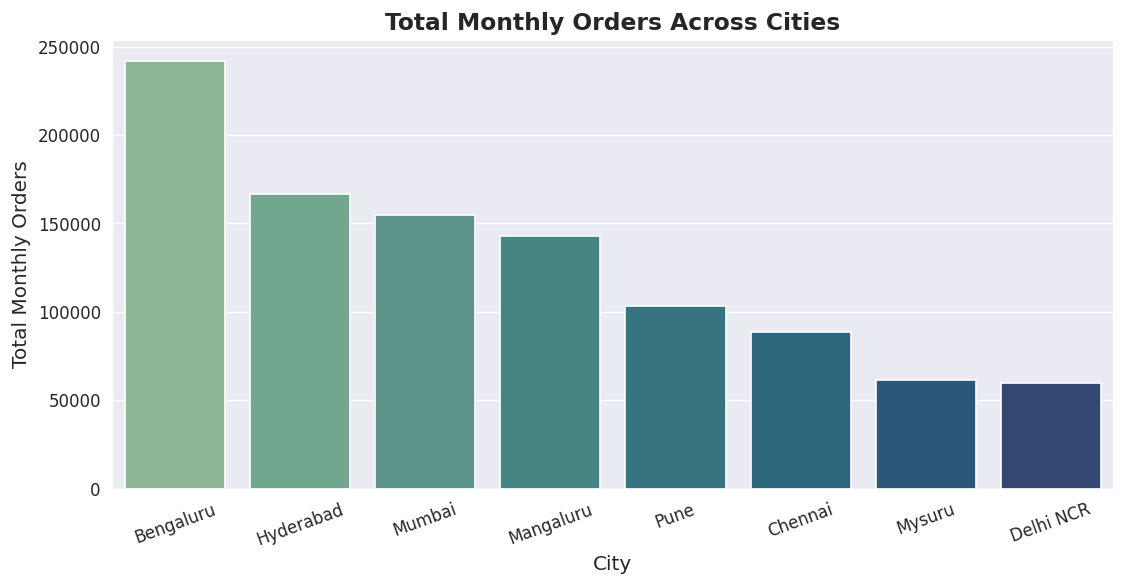

In [14]:
# Chart 1: Bar Plot of Total Monthly Orders by City
plt.figure(figsize=(9.5, 5))
sns.barplot(
    x=city_analysis.index,
    y=city_analysis["Total_Monthly_Orders"],
    hue=city_analysis.index,
    palette="crest",
    legend=False
)
plt.title("Total Monthly Orders Across Cities", fontsize=14, fontweight="bold")
plt.xlabel("City", fontsize=12)
plt.ylabel("Total Monthly Orders", fontsize=12)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

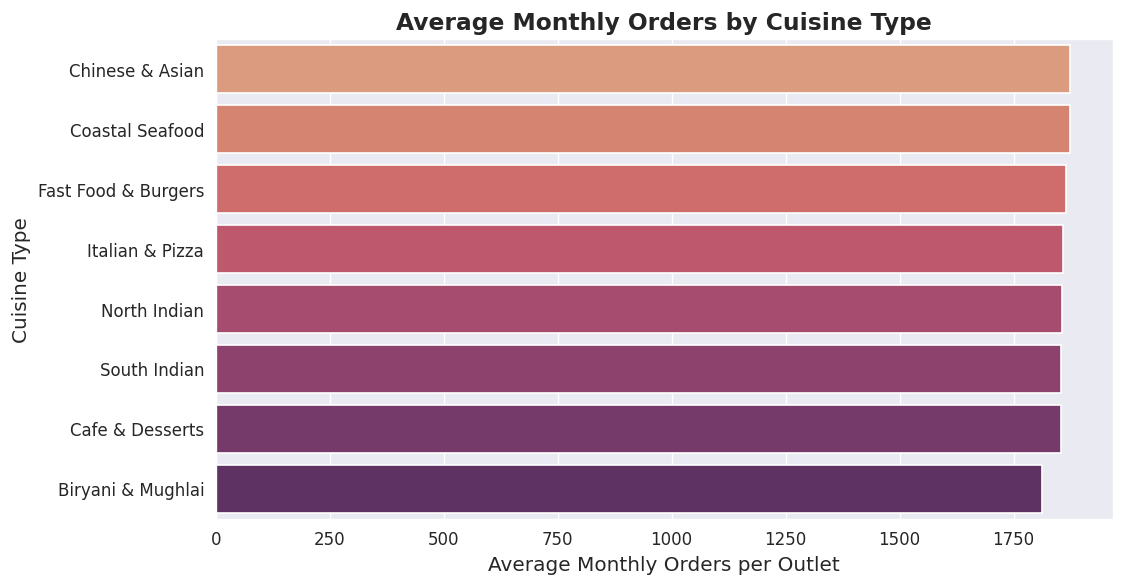

In [15]:
# Chart 2: Horizontal Bar Chart of Average Monthly Orders by Cuisine Type
plt.figure(figsize=(9.5, 5))
sns.barplot(
    x=cuisine_analysis["Avg_Monthly_Orders"],
    y=cuisine_analysis.index,
    hue=cuisine_analysis.index,
    palette="flare",
    legend=False
)
plt.title("Average Monthly Orders by Cuisine Type", fontsize=14, fontweight="bold")
plt.xlabel("Average Monthly Orders per Outlet", fontsize=12)
plt.ylabel("Cuisine Type", fontsize=12)
plt.tight_layout()
plt.show()

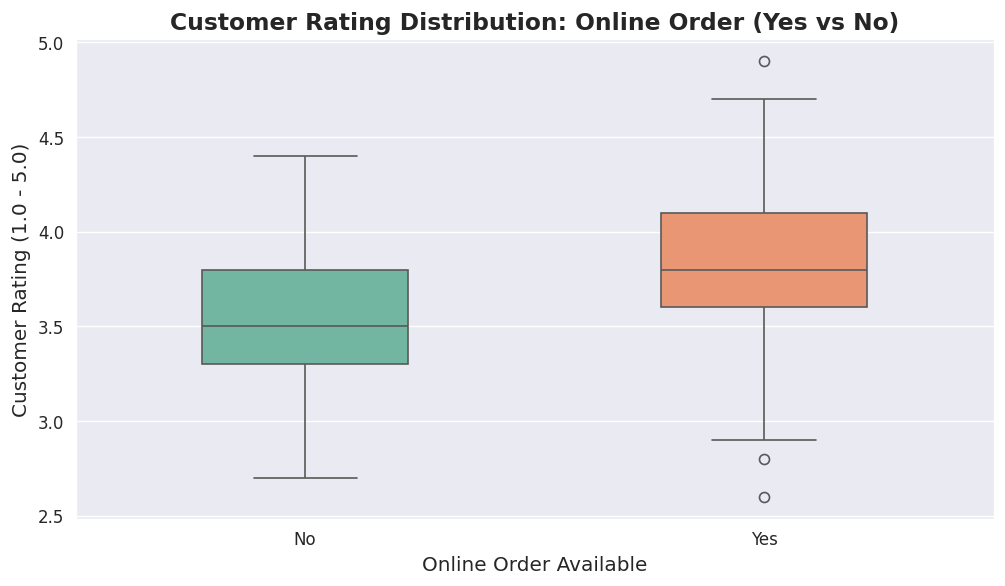

In [16]:
# Chart 3: Box Plot Comparing Customer Ratings by Online Order Availability
plt.figure(figsize=(8.5, 5))
sns.boxplot(
    data=zomato_data,
    x="Online_Order",
    y="Customer_Rating",
    hue="Online_Order",
    palette="Set2",
    width=0.45,
    legend=False
)
plt.title("Customer Rating Distribution: Online Order (Yes vs No)", fontsize=14, fontweight="bold")
plt.xlabel("Online Order Available", fontsize=12)
plt.ylabel("Customer Rating (1.0 - 5.0)", fontsize=12)
plt.tight_layout()
plt.show()

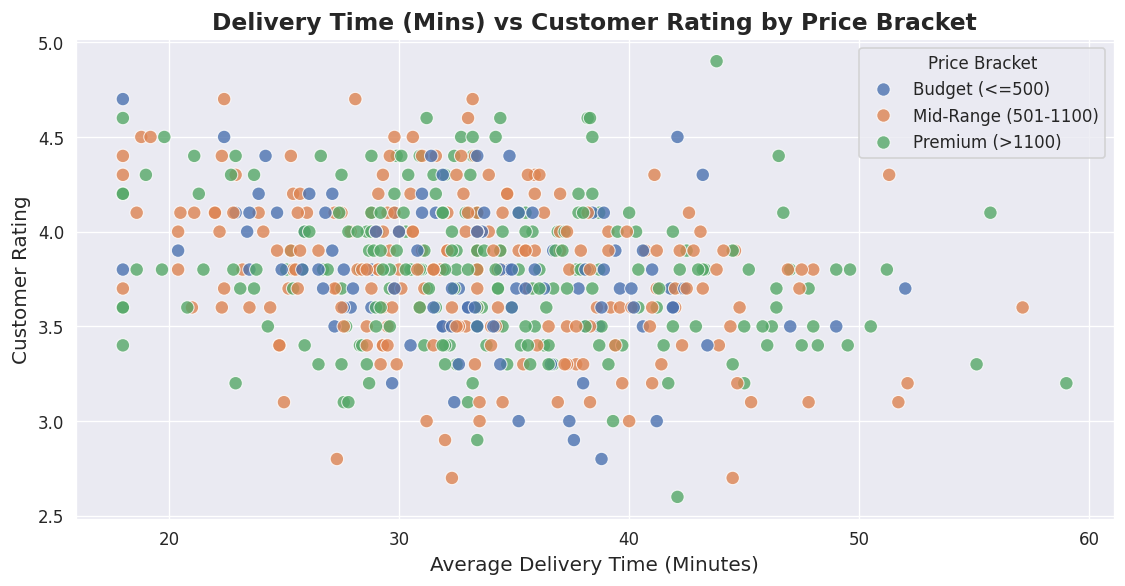

In [17]:
# Chart 4: Scatter Plot of Delivery Time vs Customer Rating across Price Brackets
plt.figure(figsize=(9.5, 5))
sns.scatterplot(
    data=zomato_data,
    x="Avg_Delivery_Time_Mins",
    y="Customer_Rating",
    hue="Price_Bracket",
    palette="deep",
    s=65,
    alpha=0.8
)
plt.title("Delivery Time (Mins) vs Customer Rating by Price Bracket", fontsize=14, fontweight="bold")
plt.xlabel("Average Delivery Time (Minutes)", fontsize=12)
plt.ylabel("Customer Rating", fontsize=12)
plt.legend(title="Price Bracket")
plt.tight_layout()
plt.show()

## Conclusion
Using Python and Pandas, we explored the 550-row `zomato_restaurants_data.csv` dataset, removed unused internal columns, converted data types and engineered new features (`Restaurant_Age_Years`, `Cost_Per_Person`, `Price_Bracket`), imputed all missing numerical values using **mean imputation**, and visualized city-wise, cuisine-wise, and delivery-time trends.